In [1]:
import pandas as pd
df = pd.read_csv('data.csv')
df

,Day,Price,Discount,Sales
0,1,100,10,250
1,2,100,0,150
2,3,90,20,300
3,4,110,0,120


In [2]:
# Input data (Features)
X = df[['Price', 'Discount']] 

# Output data (Target)
y = df['Sales']

print("X aur y alag ho gaye hain!")

X aur y alag ho gaye hain!


In [3]:
from sklearn.linear_model import LinearRegression

# Model banayein
model = LinearRegression()

# Model ko data padhayein (Train karein)
model.fit(X, y)

print("Badhai ho! Aapka model train ho gaya hai.")

Badhai ho! Aapka model train ho gaya hai.


In [4]:
# Naya data banayein
naya_data = pd.DataFrame({'Price': [105], 'Discount': [15]})

# Model se prediction puchenge
prediction = model.predict(naya_data)

print(f"Agar Price 105 aur Discount 15 hai, toh predicted Sales hogi: {prediction[0]:.2f}")

Agar Price 105 aur Discount 15 hai, toh predicted Sales hogi: 251.67


In [5]:
import pandas as pd

# Asli dataset load kar rahe hain
df = pd.read_csv('supermarket.csv') 

# Data kaisa dikhta hai, yeh dekhne ke liye shuru ki 5 lines print karein
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [6]:
# Data ke columns aur missing values ki jankari nikalna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [8]:
# dayfirst=True pandas ko batata hai ki date mein 'Din' pehle hai (jaise India/UK mein hota hai)
# errors='coerce' un dates ko hatane me madad karta hai jo bilkul hi galat format mein hain
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True, errors='coerce')

print("Date format successfully update ho gaya!")

Date format successfully update ho gaya!


In [9]:
# Jin rows mein data missing hai, unhe hata dena
df = df.dropna()
print("Missing data successfully hat gaya!")

Missing data successfully hat gaya!


In [10]:
# Date ke hisaab se Sales ko group aur sum karna
daily_sales = df.groupby('Order Date')['Sales'].sum().reset_index()

# Data ko date ke sequence mein lagana (purani date pehle, nayi baad mein)
daily_sales = daily_sales.sort_values('Order Date')

# Shuru ke 5 din ki total sales dekhne ke liye
daily_sales.head()

,Order Date,Sales
0,2015-01-03,16.448
1,2015-01-04,288.060
2,2015-01-05,19.536
3,2015-01-06,4407.100
4,2015-01-07,87.158


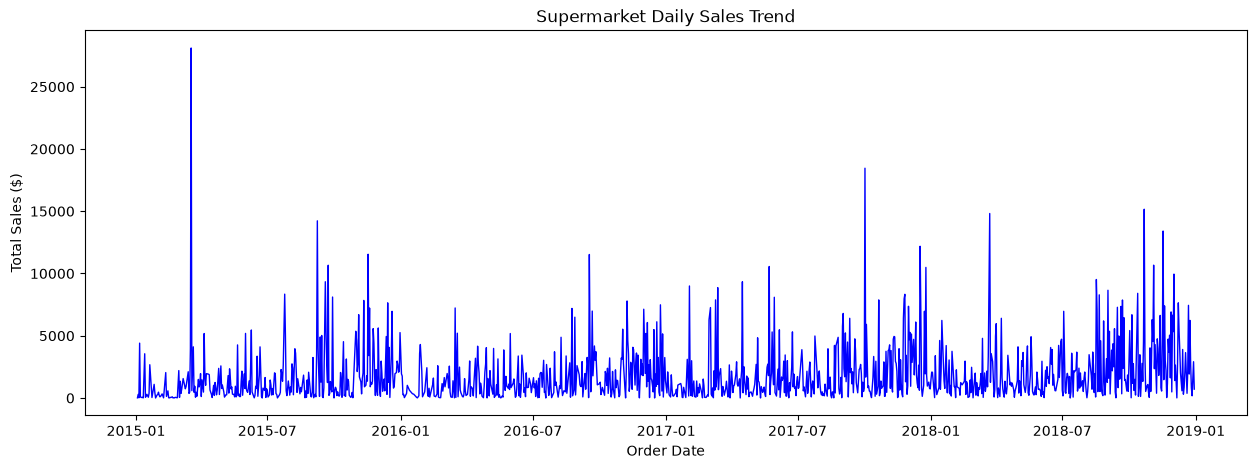

In [11]:
import matplotlib.pyplot as plt

# Graph ka size thoda bada karte hain taaki clear dikhe
plt.figure(figsize=(15, 5))

# X-axis par Date aur Y-axis par Total Sales
plt.plot(daily_sales['Order Date'], daily_sales['Sales'], color='blue', linewidth=1)

# Graph ke naam aur labels
plt.title('Supermarket Daily Sales Trend')
plt.xlabel('Order Date')
plt.ylabel('Total Sales ($)')

# Graph ko show karna
plt.show()

In [12]:
# Date column ko tod kar naye numbers wale features banana
daily_sales['Year'] = daily_sales['Order Date'].dt.year
daily_sales['Month'] = daily_sales['Order Date'].dt.month
daily_sales['Day'] = daily_sales['Order Date'].dt.day
daily_sales['DayOfWeek'] = daily_sales['Order Date'].dt.dayofweek

# X (Input) jisme ab sirf numbers hain
X = daily_sales[['Year', 'Month', 'Day', 'DayOfWeek']]

# y (Output) jo humein predict karna hai
y = daily_sales['Sales']

print("Feature Engineering successful!")

Feature Engineering successful!


In [13]:
from sklearn.model_selection import train_test_split

# Time-series mein hum purana data train ke liye aur naya data test ke liye rakhte hain (shuffle=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print("Data Train aur Test mein divide ho gaya!")

Data Train aur Test mein divide ho gaya!


In [14]:
from sklearn.ensemble import RandomForestRegressor

# Model banayein (100 chote decision trees ka combination)
ai_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Model ko 80% data par train karein
ai_model.fit(X_train, y_train)

print("Badhai ho! Aapka AI Model real data par train ho gaya hai.")

Badhai ho! Aapka AI Model real data par train ho gaya hai.


In [15]:
# Test data (X_test) par future sales ki bhavishyavani (prediction)
predictions = ai_model.predict(X_test)

print("AI ne bhavishyavani kar di hai! Ab iska test karte hain.")

AI ne bhavishyavani kar di hai! Ab iska test karte hain.


In [16]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# MAE aur RMSE nikalna
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Mean Absolute Error (MAE): 1794.04
Root Mean Squared Error (RMSE): 2533.96


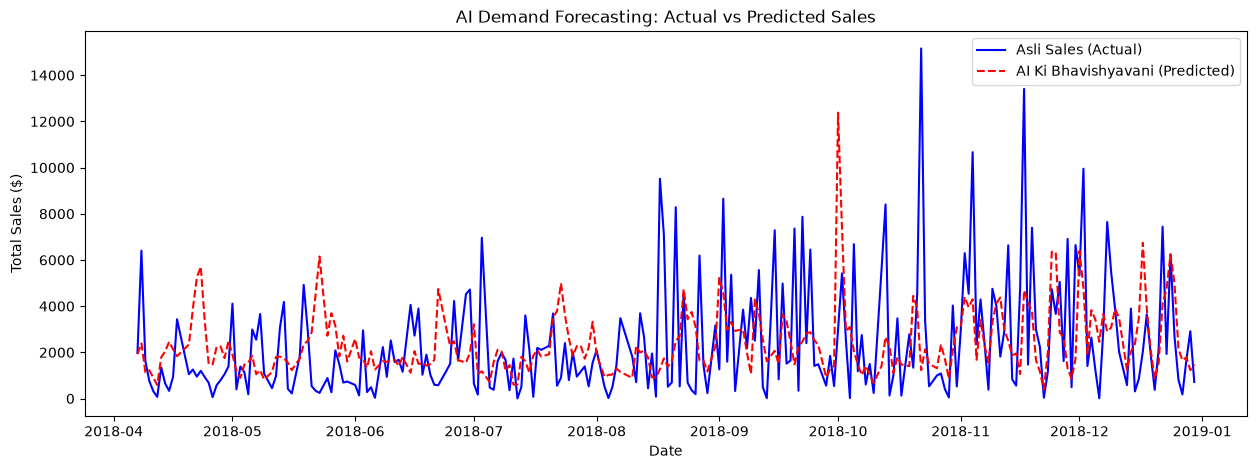

In [17]:
import matplotlib.pyplot as plt

# Graph ka size
plt.figure(figsize=(15, 5))

# Asli sales ka graph (Blue)
test_dates = daily_sales['Order Date'].iloc[-len(y_test):]
plt.plot(test_dates, y_test, label='Asli Sales (Actual)', color='blue')

# AI prediction ka graph (Red Dashed)
plt.plot(test_dates, predictions, label='AI Ki Bhavishyavani (Predicted)', color='red', linestyle='dashed')

# Labels aur Legend
plt.title('AI Demand Forecasting: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Total Sales ($)')
plt.legend()

# Graph show karein
plt.show()

In [18]:
import pickle

# Apne trained Random Forest model ko 'model.pkl' naam ki file mein save karna
with open('model.pkl', 'wb') as file:
    pickle.dump(ai_model, file)
    
print("Model successfully save ho gaya hai!")

Model successfully save ho gaya hai!
